<a href="https://colab.research.google.com/github/hassebcs2024/BSCS-2024-AI-Labs/blob/main/AI_Lab4_Hill_Climbing_N_Queens_Complete_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Lab 4 — Hill-Climbing Search (N-Queens)
I will solve the N-Queens problem with basic Hill-Climbing and Random-Restart Hill-Climbing. I will also compare results and show graphs.

## 1–3. Lab Objective and N-Queens Problem
I will put N queens on an N×N board so no two queens attack each other. Hill-Climbing will try to improve the board one step at a time.

## 4. Representing a State — Task 1
I will make a list where the index shows the column and the number shows the queen's row.

In [ ]:
# Task 1 — Create and print the state
state = [1, 3, 0, 2]
print("State:", state)

State: [1, 3, 0, 2]


## 5. Random Initial State
Now I will make a random starting board for 8 queens. I use a seed so my results stay the same when I run the whole notebook again.

In [ ]:
import random
random.seed(42)

def random_state(n):
    return [random.randrange(n) for _ in range(n)]

state = random_state(8)
print("Random initial state:", state)

Random initial state: [1, 0, 4, 3, 3, 2, 1, 1]


## 6. Evaluation Function
I will count the queens that attack each other and use the negative number of conflicts as the score. A score of 0 is best.

In [ ]:
# Count attacking pairs of queens
def count_conflicts(state):
    conflicts = 0
    n = len(state)

    for i in range(n):
        for j in range(i + 1, n):
            if state[i] == state[j]:
                conflicts += 1
            elif abs(state[i] - state[j]) == abs(i - j):
                conflicts += 1

    return conflicts

state = [1, 3, 0, 2]
print("Conflicts:", count_conflicts(state))
assert count_conflicts(state) == 0

Conflicts: 0


In [ ]:
# Evaluation score = negative conflicts
def evaluation(state):
    return -count_conflicts(state)

state = [1, 3, 0, 2]
print("Evaluation score:", evaluation(state))
assert evaluation(state) == 0

Evaluation score: 0


## 7. Generating Neighbors
Now I will move one queen to another row in the same column to make neighboring states.

In [ ]:
def get_neighbors(state):
    neighbors = []
    n = len(state)

    for col in range(n):
        for row in range(n):
            if row != state[col]:
                neighbor = state.copy()
                neighbor[col] = row
                neighbors.append(neighbor)

    return neighbors

In [ ]:
# Test the neighboring states
state = [1, 3, 0, 2]
neighbors = get_neighbors(state)
print("Number of neighbors:", len(neighbors))
print("First five neighbors:")
for neighbor in neighbors[:5]:
    print(neighbor)
print("Neighbors for 8 queens:", len(get_neighbors([0] * 8)))
assert len(neighbors) == 4 * 3
assert len(get_neighbors([0] * 8)) == 8 * 7

Number of neighbors: 12
First five neighbors:
[0, 3, 0, 2]
[2, 3, 0, 2]
[3, 3, 0, 2]
[1, 0, 0, 2]
[1, 1, 0, 2]
Neighbors for 8 queens: 56


## 8. Basic Hill-Climbing
Now I will make the Hill-Climbing function. It keeps moving to a better neighbor and stops when no improvement is possible.

In [ ]:
def hill_climbing(n):
    current = random_state(n)
    scores = []

    while True:
        current_score = evaluation(current)
        scores.append(current_score)

        neighbors = get_neighbors(current)
        best_neighbor = max(neighbors, key=evaluation)
        best_score = evaluation(best_neighbor)

        if best_score <= current_score:
            break

        current = best_neighbor

    return current, scores

## 9. Running Hill-Climbing
I will run the algorithm for 8 queens and check if it finds a board with zero conflicts.

In [ ]:
solution, scores = hill_climbing(8)
basic_solution = solution.copy()
basic_scores = scores.copy()

print("Final state:", solution)
print("Final conflicts:", count_conflicts(solution))
print("Final evaluation score:", evaluation(solution))
print("Number of iterations:", len(scores))

if count_conflicts(solution) == 0:
    print("A valid solution was found.")
else:
    print("Hill-Climbing stopped without finding a solution.")

assert all(basic_scores[i+1] >= basic_scores[i] for i in range(len(basic_scores)-1))

Final state: [6, 2, 7, 1, 4, 0, 5, 3]
Final conflicts: 0
Final evaluation score: 0
Number of iterations: 6
A valid solution was found.


## 10. Displaying the Chessboard
I will print the board to see where the queens are placed.

In [ ]:
def print_board(state):
    n = len(state)
    for row in range(n):
        line = ""
        for col in range(n):
            if state[col] == row:
                line += "Q "
            else:
                line += ". "
        print(line)

print_board(basic_solution)

. . . . . Q . . 
. . . Q . . . . 
. Q . . . . . . 
. . . . . . . Q 
. . . . Q . . . 
. . . . . . Q . 
Q . . . . . . . 
. . Q . . . . . 


## 11. Evaluation Score Graph
Now I will plot the evaluation score of my first Hill-Climbing run to see how it improves.

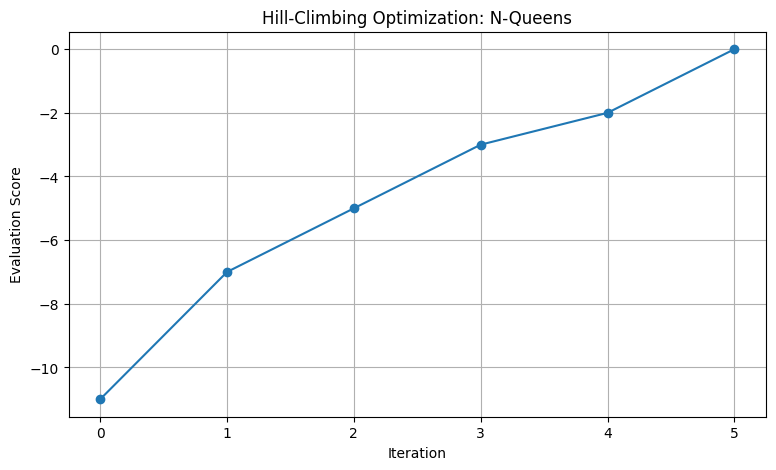

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(range(len(basic_scores)), basic_scores, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Evaluation Score")
plt.title("Hill-Climbing Optimization: N-Queens")
plt.grid(True)
plt.show()

### Graph Questions — Answers
1. **Yes.** The score increases when I move to a better board.
2. **No.** My program accepts only moves with higher scores.
3. **It stops** when no better neighbor is found.
4. **Zero** means no queens attack each other.
5. **Yes.** It can stop below zero when it gets stuck at a non-solution local maximum.

## 12. Different Board Sizes — Task 2
I will try N = 4, 8, 10, and 12, then record more runs in a results table.

In [ ]:
# Try each board size once
for n in [4, 8, 10, 12]:
    board, history = hill_climbing(n)
    print(
        f"N = {n:2d} | "
        f"Conflicts = {count_conflicts(board):2d} | "
        f"Iterations = {len(history):3d} | "
        f"Solved = {count_conflicts(board) == 0}"
    )

N =  4 | Conflicts =  1 | Iterations =   2 | Solved = False
N =  8 | Conflicts =  1 | Iterations =   4 | Solved = False
N = 10 | Conflicts =  1 | Iterations =   5 | Solved = False
N = 12 | Conflicts =  2 | Iterations =   6 | Solved = False


In [ ]:
# Task 2 — Record repeated runs
import pandas as pd

size_runs = {4: 2, 8: 3, 10: 3, 12: 2}
board_size_results = []

for n, number_of_runs in size_runs.items():
    for run in range(1, number_of_runs + 1):
        board, history = hill_climbing(n)
        conflicts = count_conflicts(board)
        board_size_results.append({
            "N": n,
            "Run": run,
            "Final Conflicts": conflicts,
            "Iterations": len(history),
            "Solved?": conflicts == 0
        })

board_size_table = pd.DataFrame(board_size_results)
print(board_size_table.to_string(index=False))

 N  Run  Final Conflicts  Iterations  Solved?
 4    1                1           2    False
 4    2                1           3    False
 8    1                1           4    False
 8    2                1           5    False
 8    3                2           3    False
10    1                2           4    False
10    2                1           5    False
10    3                2           5    False
12    1                3           5    False
12    2                2           7    False


**My observation:** The same board size can give different results because each run begins with a different random board.

## 13–14. Random-Restart Hill-Climbing
Now I will try Hill-Climbing again from new random states if the first attempt does not solve the board.

In [ ]:
def random_restart_hill_climbing(n, max_restarts=100):
    best_state = None
    best_score = float("-inf")
    best_scores = []

    for restart in range(max_restarts):
        state, scores = hill_climbing(n)
        score = evaluation(state)

        if score > best_score:
            best_state = state
            best_score = score

        best_scores.append(best_score)

        if best_score == 0:
            return best_state, restart + 1, best_scores

    return best_state, max_restarts, best_scores

In [ ]:
# Run Random-Restart for 8 queens
restart_solution, restarts, best_scores = random_restart_hill_climbing(8, max_restarts=100)
print("Final state:", restart_solution)
print("Final conflicts:", count_conflicts(restart_solution))
print("Restarts performed:", restarts)

if count_conflicts(restart_solution) == 0:
    print("A valid solution was found.")
else:
    print("No solution was found within the restart limit.")

print_board(restart_solution)
assert all(best_scores[i+1] >= best_scores[i] for i in range(len(best_scores)-1))

Final state: [5, 2, 4, 7, 0, 3, 1, 6]
Final conflicts: 0
Restarts performed: 4
A valid solution was found.
. . . . Q . . . 
. . . . . . Q . 
. Q . . . . . . 
. . . . . Q . . 
. . Q . . . . . 
Q . . . . . . . 
. . . . . . . Q 
. . . Q . . . . 


## 15. Random-Restart Graph
I will plot the best score found after each restart. It cannot go down because I save the best result.

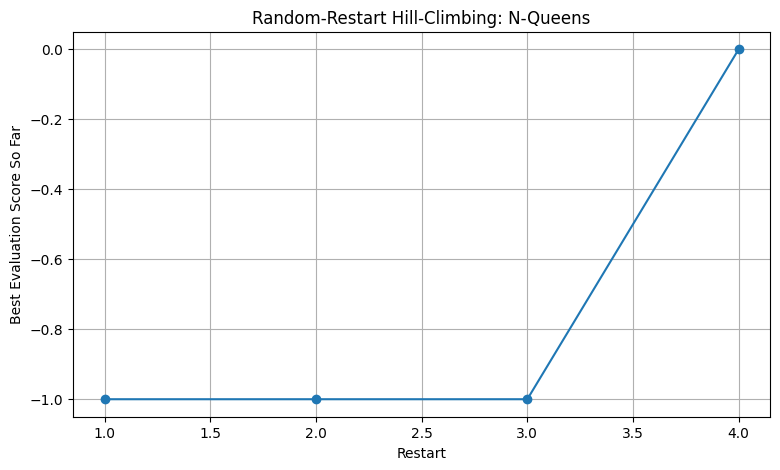

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(best_scores) + 1), best_scores, marker="o")
plt.xlabel("Restart")
plt.ylabel("Best Evaluation Score So Far")
plt.title("Random-Restart Hill-Climbing: N-Queens")
plt.grid(True)
plt.show()

## 16. Comparing Both Algorithms — Task 3
I will run basic Hill-Climbing and Random-Restart Hill-Climbing five times each and compare the results.

In [ ]:
# Five runs of each algorithm
comparison_results = []

print("Basic Hill-Climbing")
print("-------------------")
for i in range(5):
    state, history = hill_climbing(8)
    conflicts = count_conflicts(state)
    comparison_results.append({"Algorithm": "Basic", "Run": i + 1,
                               "Conflicts": conflicts, "Attempts": 1,
                               "Iterations": len(history), "Solved?": conflicts == 0})
    print(f"Run {i + 1}: Conflicts = {conflicts}, Iterations = {len(history)}, Solved = {conflicts == 0}")

print("\nRandom-Restart Hill-Climbing")
print("----------------------------")
for i in range(5):
    state, attempts, history = random_restart_hill_climbing(8, max_restarts=100)
    conflicts = count_conflicts(state)
    comparison_results.append({"Algorithm": "Random-Restart", "Run": i + 1,
                               "Conflicts": conflicts, "Attempts": attempts,
                               "Iterations": None, "Solved?": conflicts == 0})
    print(f"Run {i + 1}: Conflicts = {conflicts}, Restarts = {attempts}, Solved = {conflicts == 0}")

comparison_table = pd.DataFrame(comparison_results)

Basic Hill-Climbing
-------------------
Run 1: Conflicts = 1, Iterations = 5, Solved = False
Run 2: Conflicts = 1, Iterations = 5, Solved = False
Run 3: Conflicts = 3, Iterations = 2, Solved = False
Run 4: Conflicts = 1, Iterations = 5, Solved = False
Run 5: Conflicts = 0, Iterations = 5, Solved = True

Random-Restart Hill-Climbing
----------------------------
Run 1: Conflicts = 0, Restarts = 2, Solved = True
Run 2: Conflicts = 0, Restarts = 8, Solved = True
Run 3: Conflicts = 0, Restarts = 3, Solved = True
Run 4: Conflicts = 0, Restarts = 4, Solved = True
Run 5: Conflicts = 0, Restarts = 4, Solved = True


In [ ]:
# Task 3 — Results table and answers based on my runs
print(comparison_table.to_string(index=False))

basic = comparison_table[comparison_table["Algorithm"] == "Basic"]
restarted = comparison_table[comparison_table["Algorithm"] == "Random-Restart"]
basic_successes = int(basic["Solved?"].sum())
restart_successes = int(restarted["Solved?"].sum())
restart_counts = restarted["Attempts"].tolist()
limit_failures = int(((restarted["Attempts"] == 100) & (~restarted["Solved?"])).sum())

print("\nTask 3 Answers:")
print(f"1. Basic Hill-Climbing solved {basic_successes} out of 5 runs. "
      f"{'It did not solve every run.' if basic_successes < 5 else 'It solved every run in this experiment.'}")
print(f"2. Random-Restart solved {restart_successes} out of 5 runs "
      f"(basic solved {basic_successes} out of 5).")
print(f"3. Restarts used for the five runs: {restart_counts}")
print(f"4. Runs that reached 100 attempts without a solution: {limit_failures}")
print("5. New starting states give more chances to solve the problem, "
      "but 100 attempts still cannot guarantee success.")

     Algorithm  Run  Conflicts  Attempts  Iterations  Solved?
         Basic    1          1         1         5.0    False
         Basic    2          1         1         5.0    False
         Basic    3          3         1         2.0    False
         Basic    4          1         1         5.0    False
         Basic    5          0         1         5.0     True
Random-Restart    1          0         2         NaN     True
Random-Restart    2          0         8         NaN     True
Random-Restart    3          0         3         NaN     True
Random-Restart    4          0         4         NaN     True
Random-Restart    5          0         4         NaN     True

Task 3 Answers:
1. Basic Hill-Climbing solved 1 out of 5 runs. It did not solve every run.
2. Random-Restart solved 5 out of 5 runs (basic solved 1 out of 5).
3. Restarts used for the five runs: [2, 8, 3, 4, 4]
4. Runs that reached 100 attempts without a solution: 0
5. New starting states give more chances to solve 

## 17. Lab Questions — My Answers

1. **Evaluation function:** I use it to check which board has fewer attacking queens.
2. **Best score:** Zero is best because there are no conflicts left.
3. **Local vs global maximum:** A local maximum is better than nearby states; a global maximum is best overall.
4. **Why basic search can stop:** It may reach a board where no neighbor has a better score.
5. **Is a local maximum always failure?** No. It is a success if the score is zero.
6. **Neighbors for N = 8:** There are `8 × 7 = 56` neighbors.
7. **What the graph shows:** It shows my score improving until the algorithm stops.
8. **Probabilistic completeness:** With enough independent tries, the chance of finding a solution can approach 100% if each try has a chance of success.
9. **Why restart helps:** I get new starting positions, so I have more chances to find a solution.
10. **Guaranteed within 100 restarts?** No. The algorithm can still fail after 100 attempts.

## 18. Extension Task — N = 20
Now I will try 20 queens with both algorithms and compare conflicts, iterations, and restarts.

In [ ]:
# Extension — Basic Hill-Climbing with N = 20
n20_basic_state, n20_basic_scores = hill_climbing(20)
n20_basic_conflicts = count_conflicts(n20_basic_state)
print("Basic Hill-Climbing (N=20)")
print("Final state:", n20_basic_state)
print("Final conflicts:", n20_basic_conflicts)
print("Iterations:", len(n20_basic_scores))
print("Solved:", n20_basic_conflicts == 0)

Basic Hill-Climbing (N=20)
Final state: [7, 11, 14, 1, 15, 5, 2, 4, 10, 17, 19, 16, 3, 12, 18, 6, 8, 0, 13, 9]
Final conflicts: 1
Iterations: 12
Solved: False


In [ ]:
# Extension — Random-Restart Hill-Climbing with N = 20
n20_restart_state, n20_restarts, n20_best_scores = random_restart_hill_climbing(20, max_restarts=100)
n20_restart_conflicts = count_conflicts(n20_restart_state)
print("Random-Restart Hill-Climbing (N=20)")
print("Final state:", n20_restart_state)
print("Final conflicts:", n20_restart_conflicts)
print("Restarts used:", n20_restarts)
print("Solved:", n20_restart_conflicts == 0)

print("\nN=20 Comparison")
print(pd.DataFrame([
    {"Algorithm": "Basic", "Conflicts": n20_basic_conflicts,
     "Iterations": len(n20_basic_scores), "Restarts": 1,
     "Solved?": n20_basic_conflicts == 0},
    {"Algorithm": "Random-Restart", "Conflicts": n20_restart_conflicts,
     "Iterations": "Different for each run", "Restarts": n20_restarts,
     "Solved?": n20_restart_conflicts == 0}
]).to_string(index=False))

Random-Restart Hill-Climbing (N=20)
Final state: [11, 9, 19, 6, 2, 15, 10, 8, 4, 18, 16, 13, 7, 5, 0, 14, 1, 17, 12, 3]
Final conflicts: 0
Restarts used: 4
Solved: True

N=20 Comparison
     Algorithm  Conflicts             Iterations  Restarts  Solved?
         Basic          1                     12         1    False
Random-Restart          0 Different for each run         4     True


**My observation:** With 20 queens, each board has more possible moves, so the search takes more work. A random start may get stuck, while restarts give me more chances to find a valid board.

## 19. Conclusion
I completed basic and Random-Restart Hill-Climbing for N-Queens. Basic search can get stuck, but repeated random starts usually improve my chances of solving the problem.